In [1]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Current device is :{device}")

Current device is :cpu


In [3]:
transform = v2.Compose([v2.ToImage(),v2.ToDtype(torch.float32, scale=True)])
training_data = datasets.MNIST(root="data",train=True,download=True,transform=transform)
test_data = datasets.MNIST(root="data",train=False,download=True,transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 410kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.74MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.11MB/s]


In [5]:
batch_size = 100
num_workers = 2
train_dataloader = DataLoader(training_data, batch_size, shuffle = True, num_workers = num_workers)
test_dataloader =DataLoader(test_data, batch_size, num_workers = num_workers)

In [6]:
images, labels = next(iter(train_dataloader))
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image data type:", images.dtype)
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Images shape: torch.Size([100, 1, 28, 28])
Labels shape: torch.Size([100])
Image data type: torch.float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [13]:
class CNNDIGIT(nn.Module):
  def __init__(self):
    super().__init__()
    self.cnn_relu = nn.Sequential(nn.Conv2d(1,32, kernel_size=3, stride = 1, padding = 1),nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(32,64,kernel_size=3, stride = 1, padding = 1),nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(64,128,kernel_size=3, stride = 1, padding = 1),nn.ReLU(), nn.MaxPool2d(2))
    self.flatten = nn.Flatten()
    self.classifier = nn.Sequential(nn.Linear(128*3*3,100),nn.ReLU(),nn.Linear(100,10))
  def forward(self,x):
    x = self.cnn_relu(x)
    x = self.flatten(x)
    logits = self.classifier(x)
    return logits

model = CNNDIGIT().to(device)
print(model)

CNNDIGIT(
  (cnn_relu): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=1152, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=10, bias=True)
  )
)


In [14]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr = 0.001)

In [21]:
def train(train_data, model, loss_fn, optimizer):
  size = len(train_data.dataset)
  print(size)
  model.train()
  for batch, (X, y) in enumerate(train_data):
    X = X.to(device)
    y = y.to(device)
    pred = model(X)
    loss = loss_fn(pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if batch % 100 == 0:
       loss, current = loss.item(), (batch + 1) * len(X)
       print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


In [22]:
def test(test_data, model, loss_fn):
    size = len(test_data.dataset)
    num_batches = len(test_data)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in test_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [23]:
epochs = 5
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
60000
loss: 2.301512  [  100/60000]
loss: 0.294152  [10100/60000]
loss: 0.211458  [20100/60000]
loss: 0.130969  [30100/60000]
loss: 0.191225  [40100/60000]
loss: 0.240515  [50100/60000]
Test Error: 
 Accuracy: 97.9%, Avg loss: 0.064346 

Epoch 2
-------------------------------
60000
loss: 0.045339  [  100/60000]
loss: 0.066409  [10100/60000]
loss: 0.048613  [20100/60000]
loss: 0.098545  [30100/60000]
loss: 0.056937  [40100/60000]
loss: 0.045347  [50100/60000]
Test Error: 
 Accuracy: 98.3%, Avg loss: 0.051528 

Epoch 3
-------------------------------
60000
loss: 0.041565  [  100/60000]
loss: 0.022997  [10100/60000]
loss: 0.017204  [20100/60000]
loss: 0.007562  [30100/60000]
loss: 0.010122  [40100/60000]
loss: 0.036862  [50100/60000]
Test Error: 
 Accuracy: 99.1%, Avg loss: 0.029820 

Epoch 4
-------------------------------
60000
loss: 0.003090  [  100/60000]
loss: 0.024410  [10100/60000]
loss: 0.041465  [20100/60000]
loss: 0.006900  [30100/60000]


In [24]:
model.eval()
y_true = []
y_pred = []
with torch.no_grad():
    for X, y in test_dataloader:
        X = X.to(device)
        pred = model(X)
        predicted = pred.argmax(1)
        y_true.extend(y.numpy())
        y_pred.extend(predicted.cpu().numpy())

In [25]:
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

Saved PyTorch Model State to model.pth


In [26]:
model = CNNDIGIT().to(device)
model.load_state_dict(torch.load("model.pth", weights_only=True))

<All keys matched successfully>

In [29]:
classes = ["0","1","2","3","4","5","6","7","8","9",]
model.eval()
x, y = test_data[0][0], test_data[0][1]
with torch.no_grad():
    x = x.unsqueeze(0).to(device)
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

Predicted: "7", Actual: "7"


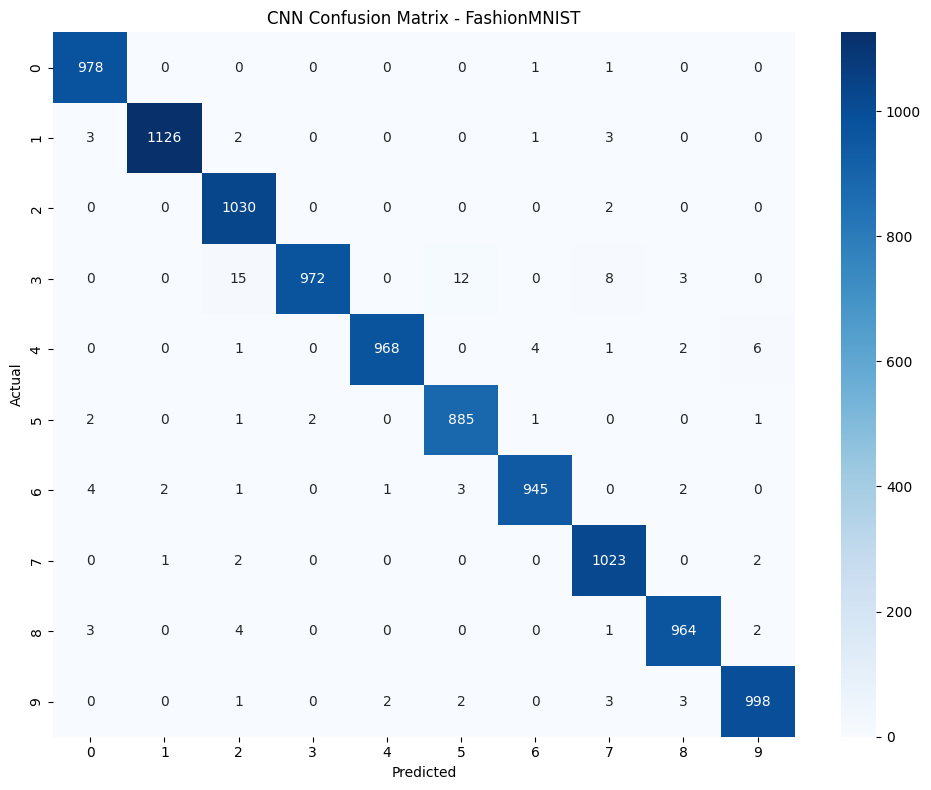

In [30]:
classes = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix - FashionMNIST")
plt.tight_layout()
plt.show()

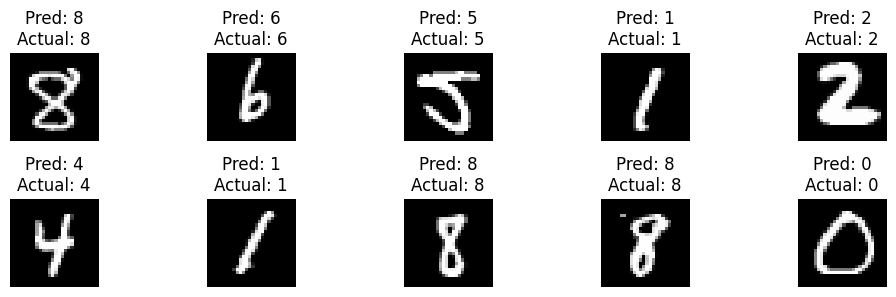

In [33]:
import random
model.eval()
plt.figure(figsize=(10, 6))
for i in range(10):
    index = random.randint(0, len(test_data)-1)
    x, y = test_data[index]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(device))
        predicted = classes[pred.argmax(1).item()]
    plt.subplot(4, 5, i+1)
    plt.imshow(x.squeeze(), cmap="gray")
    plt.title(f"Pred: {predicted}\nActual: {classes[y]}")
    plt.axis("off")
plt.tight_layout()
plt.show()